# BITS Machine Learning Assignment 2 — Guided Experiment

**Learning notebook.** Run all cells in the BITS Virtual Lab and capture your own execution screenshot. Dataset: UCI Breast Cancer Wisconsin Diagnostic, accessed through scikit-learn. 569 rows, 30 numeric features, two target classes. This is a dataset of cell measurements, not an independent medical diagnostic tool.

## 1. Goal and evaluation setup
Compare five classification models on the **same stratified 80/20 split** (random_state=42). In this notebook, malignant=1 is the positive class. The six metrics are accuracy, ROC AUC, precision, recall, F1, and MCC. Preprocessing stays inside training-only fitted pipelines to avoid test leakage.

In [1]:
from pathlib import Path
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from IPython.display import display

base = Path.cwd()
data = load_breast_cancer(as_frame=True)
X = data.data
y = (data.target == 0).astype(int)  # malignant=1, benign=0
print(f"Dataset shape: {X.shape}")
print("Class counts (0=benign, 1=malignant):")
print(y.value_counts().sort_index())
display(X.head(3))

Dataset shape: (569, 30)
Class counts (0=benign, 1=malignant):
target
0    357
1    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


## 2. Train the five models and save artifacts
The script contains the five models and is intentionally kept separately from the Streamlit frontend. It also exports `test_data.csv`, the comparison table, and trained models. You can inspect the Python source in Jupyter.

In [2]:
import subprocess, sys
result = subprocess.run([sys.executable, str(base / "train_models.py")], cwd=base, capture_output=True, text=True)
print(result.stdout)
if result.returncode:
    print(result.stderr)
    raise RuntimeError("Training script failed")

Training: 455 Test: 114
                 Model  Accuracy    AUC  Precision  Recall     F1    MCC
   Logistic Regression    0.9649 0.9960     0.9750  0.9286 0.9512 0.9245
         Decision Tree    0.9211 0.9448     0.9459  0.8333 0.8861 0.8299
                   KNN    0.9561 0.9823     0.9744  0.9048 0.9383 0.9058
           Naive Bayes    0.9386 0.9934     1.0000  0.8333 0.9091 0.8715
Support Vector Machine    0.9737 0.9947     1.0000  0.9286 0.9630 0.9442

Best test F1: Support Vector Machine



## 3. Inspect the comparison table

In [3]:
comparison = pd.read_csv(base / "model_comparison.csv")
display(comparison.round(4).sort_values("F1", ascending=False))

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
4,Support Vector Machine,0.9737,0.9947,1.0000,0.9286,0.9630,0.9442
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
2,KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058
3,Naive Bayes,0.9386,0.9934,1.0000,0.8333,0.9091,0.8715
1,Decision Tree,0.9211,0.9448,0.9459,0.8333,0.8861,0.8299


## 4. Visualize model performance

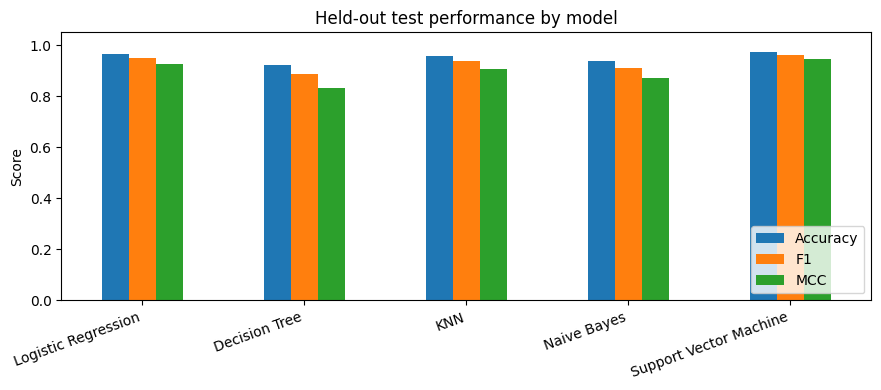

In [4]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(9,4))
comparison.plot.bar(x="Model",y=["Accuracy","F1","MCC"],ax=ax)
ax.set_title("Held-out test performance by model")
ax.set_ylim(0,1.05)
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.legend(loc="lower right")
plt.xticks(rotation=20,ha="right")
plt.tight_layout()
plt.show()

## 5. Discussion prompts for your own README
- Which algorithm had the best F1, and was it also highest in AUC?
- How does decision-tree performance compare with the scaled models?
- Why is malignant recall important for this example?
- Does a single 80/20 split establish that the winner is universally best? (No; discuss sampling variability.)
- Record any changes you make in the notebook and commit history.

**Academic integrity:** BITS asks that AI be used for learning support, not direct copy-paste submission. Personalize your experiment and write observations based on results you produce in the Virtual Lab.

## 6. Next steps
Open a terminal in the working directory and run `streamlit run app.py` (after installing `requirements.txt`). Upload the generated `test_data.csv` and choose a model. No training occurs in the app.